In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\SWAPNA JEBBNOLLA\OneDrive\New Folder\All projects of internshala\Python Project\ebay.csv")

df.head()

,Timestamp,age,Gender,Purchase_Frequency,Purchase_Categories,Personalized_Recommendation_Frequency,Browsing_Frequency,Product_Search_Method,Search_Result_Exploration,Customer_Reviews_Importance,...,Review_Left,Review_Reliability,Review_Helpfulness,Personalized_Recommendation_Frequency,Recommendation_Helpfulness,Rating_Accuracy,Shopping_Satisfaction,Service_Appreciation,Improvement_Areas,transaction
0,2023/06/07 11:44:55 AM GMT+5:30,32,Prefer not to say,Multiple times a week,Groceries and Gourmet Food;Home and Kitchen,Sometimes,Rarely,categories,Multiple pages,5,...,Yes,Never,Yes,5,Yes,1,1,Customer service,.,819284
1,2023/06/07 9:28:09 AM GMT+5:30,47,Female,Multiple times a week,Groceries and Gourmet Food;Beauty and Personal...,No,Few times a month,NaN,First page,5,...,Yes,Never,Sometimes,2,Yes,4,4,User-friendly website/app interface,Shipping speed and reliability,599249
2,2023/06/05 10:09:03 PM GMT+5:30,50,Female,Once a month,Groceries and Gourmet Food;Beauty and Personal...,Sometimes,Multiple times a day,categories,Multiple pages,1,...,Yes,Rarely,Sometimes,1,Sometimes,4,2,Customer service,Reducing packaging waste,432245
3,2023/06/07 5:58:12 PM GMT+5:30,6,Others,Once a month,Groceries and Gourmet Food;Beauty and Personal...,No,Rarely,others,Multiple pages,1,...,No,Heavily,No,2,Yes,4,4,Product recommendations,Irrelevant product suggestions,476517
4,2023/06/07 11:46:52 AM GMT+5:30,61,Male,Once a week,Groceries and Gourmet Food;Clothing and Fashion,Yes,Rarely,NaN,Multiple pages,5,...,No,Never,Yes,2,No,3,2,Product recommendations,Shipping speed and reliability,894659


In [2]:
df.shape

(800, 24)

In [3]:
# Task 1: Data Cleaning and Preparation..........
# Remove duplicate or inconsistent survey responses.

df.duplicated().sum()

df = df.drop_duplicates()

In [4]:
# Standardize categorical/numerical entries (e.g., frequency levels, gender, 
# recommendation responses).

df["Gender"] = df["Gender"].str.strip().str.title()

df["Purchase_Frequency"] = df["Purchase_Frequency"].str.strip().str.title()

df["Personalized_Recommendation_Frequency"] = df["Personalized_Recommendation_Frequency"].str.strip().str.title()

df["Product_Search_Method"] = df["Product_Search_Method"].str.strip().str.title()

df["Recommendation_Helpfulness"] = df["Recommendation_Helpfulness"].str.strip().str.title()

In [5]:
# For Handling missing values

df.isnull().sum()

Timestamp                                   0
age                                         0
Gender                                      0
Purchase_Frequency                          0
Purchase_Categories                         0
Personalized_Recommendation_Frequency       0
Browsing_Frequency                          0
Product_Search_Method                     161
Search_Result_Exploration                   0
Customer_Reviews_Importance                 0
Add_to_Cart_Browsing                        0
Cart_Completion_Frequency                   0
Cart_Abandonment_Factors                    0
Saveforlater_Frequency                      0
Review_Left                                 0
Review_Reliability                          0
Review_Helpfulness                          0
Personalized_Recommendation_Frequency       0
Recommendation_Helpfulness                  0
Rating_Accuracy                             0
Shopping_Satisfaction                       0
Service_Appreciation              

In [6]:
# Handle missing values and inconsistent formats in Product_Search_Method and other 
# fields.
# Check missing values
df.isnull().sum()

# Fill missing values
df["Product_Search_Method"] = df["Product_Search_Method"].fillna("No Search")

# Remove extra spaces from text values
df["Product_Search_Method"] = df["Product_Search_Method"].str.strip().str.title()

In [7]:
# Rename duplicate or misformatted columns (e.g., remove trailing spaces in 
# Rating_Accuracy ).
# Remove leading and trailing spaces from all column names
df.columns = df.columns.str.strip()

# Check updated column names
df.columns

# Remove duplicate column names
df = df.loc[:, ~df.columns.duplicated()]

In [8]:
# Convert numerical rating columns (e.g., Customer_Reviews_Importance, 
# Shopping_Satisfaction) to appropriate numeric types for analysis. 
# Convert rating columns to numeric data type

df["Customer_Reviews_Importance"] = pd.to_numeric(df["Customer_Reviews_Importance"], errors="coerce")

df["Rating_Accuracy"] = pd.to_numeric(df["Rating_Accuracy"], errors="coerce")

df["Shopping_Satisfaction"] = pd.to_numeric(df["Shopping_Satisfaction"], errors="coerce")

In [9]:
# Task 2: Descriptive Behavior Analysis..................
# Summarize customer demographics (age, gender distribution).
# Gender Distribution

df["Gender"].value_counts()

Gender
Others               209
Prefer Not To Say    202
Female               198
Male                 191
Name: count, dtype: int64

In [10]:
# Age Distribution

df["age"].describe()

count    800.000000
mean      35.730000
std       18.588141
min        3.000000
25%       19.000000
50%       37.000000
75%       52.000000
max       67.000000
Name: age, dtype: float64

In [11]:
# Analyze overall purchase frequency and most popular product categories. 
# Purchase Frequency Distribution

df["Purchase_Frequency"].value_counts()

Purchase_Frequency
Few Times A Month         172
Less Than Once A Month    172
Once A Month              160
Multiple Times A Week     148
Once A Week               148
Name: count, dtype: int64

In [12]:
# Separate multiple categories and count individual categories
# Most popular product categories. 

category_count = df["Purchase_Categories"].str.split(";").explode().value_counts()

category_count

Purchase_Categories
Clothing and Fashion          450
Home and Kitchen              421
Beauty and Personal Care      418
others                        390
Groceries and Gourmet Food    366
Name: count, dtype: int64

In [13]:
# Identify top browsing methods and most common cart abandonment factors.
# Top browsing methods

df["Product_Search_Method"].value_counts().idxmax()

'Keyword'

In [14]:
 # Most common cart abandonment factors

df["Cart_Abandonment_Factors"].value_counts().idxmax()

'High shipping costs'

In [15]:
# Calculate mean and median satisfaction, recommendation helpfulness, and rating 
#accuracy. 

# Converting Recommendation_Helpfulness Into 1-3 Sale.

recommendation_map = {
    "No": 1,
    "Sometimes": 2,
    "Yes": 3
}

df["Recommendation_Helpfulness"] = df["Recommendation_Helpfulness"].map(recommendation_map)


In [16]:
# Mean()

df[["Shopping_Satisfaction",
    "Recommendation_Helpfulness",
    "Rating_Accuracy"]].mean()

Shopping_Satisfaction         2.86625
Recommendation_Helpfulness    1.98625
Rating_Accuracy               3.08625
dtype: float64

In [17]:
# Median

df[["Shopping_Satisfaction",
    "Recommendation_Helpfulness",
    "Rating_Accuracy"]].median()

Shopping_Satisfaction         3.0
Recommendation_Helpfulness    2.0
Rating_Accuracy               3.0
dtype: float64

In [18]:
# Generate summary statistics and visualizations for key behavioral variables.
# Summary statistics.

df[["Rating_Accuracy",
    "Shopping_Satisfaction",
    "Recommendation_Helpfulness"]].describe()

,Rating_Accuracy,Shopping_Satisfaction,Recommendation_Helpfulness
count,800.000000,800.000000,800.000000
mean,3.086250,2.866250,1.986250
std,1.420857,1.429481,0.822744
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,1.000000
50%,3.000000,3.000000,2.000000
75%,4.000000,4.000000,3.000000
max,5.000000,5.000000,3.000000


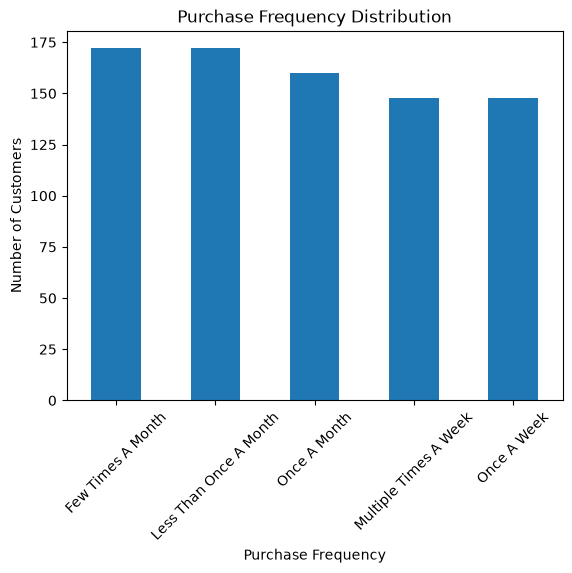

In [19]:
# Visualizations for key behavioral variables.
# Purchase Frequency Visualization.

import matplotlib.pyplot as plt

df["Purchase_Frequency"].value_counts().plot(kind="bar")

plt.title("Purchase Frequency Distribution")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()

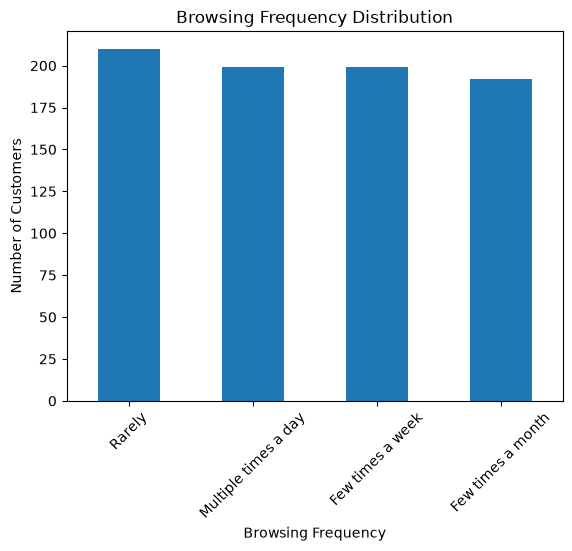

In [20]:
# Browsing Frequency Visualization

df["Browsing_Frequency"].value_counts().plot(kind="bar")

plt.title("Browsing Frequency Distribution")
plt.xlabel("Browsing Frequency")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()

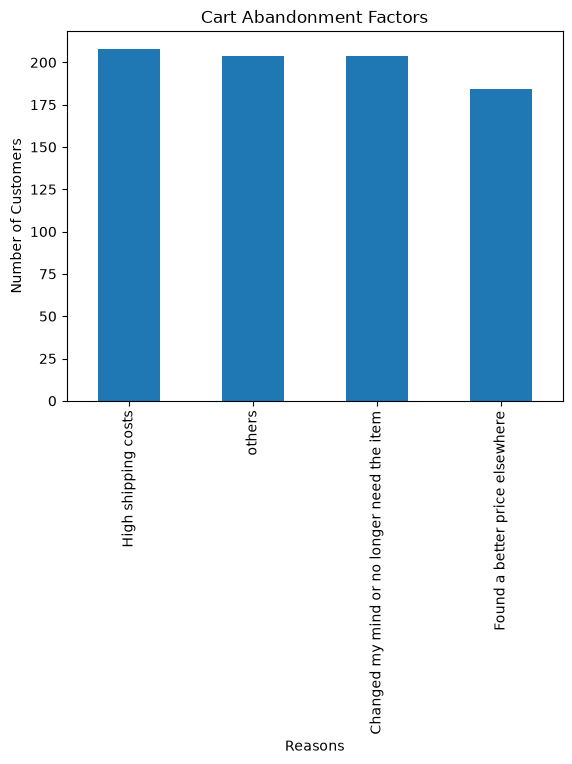

In [21]:
# Cart Abandonment Factors Visualization

df["Cart_Abandonment_Factors"].value_counts().plot(kind="bar")

plt.title("Cart Abandonment Factors")
plt.xlabel("Reasons")
plt.ylabel("Number of Customers")
plt.xticks(rotation=90)
plt.show()

In [ ]:
# Task 3: Customer Segmentation and Profiling..........................
# Segment customers based on purchase frequency and shopping satisfaction levels.
# Create profiles such as:
# Frequent Buyers: High purchase frequency, high satisfaction.
# Occasional Shoppers: Medium frequency, moderate satisfaction.
# At-Risk Customers: Low satisfaction or frequent cart abandonment.
import numpy as np

df["Purchase_Frequency_Score"] = np.select(
    [
        df["Purchase_Frequency"].str.contains("Multiple times", case=False, na=False),
        df["Purchase_Frequency"].str.contains("Once a week", case=False, na=False),
        df["Purchase_Frequency"].str.contains("Few times a month", case=False, na=False),
        df["Purchase_Frequency"].str.contains("Once a month", case=False, na=False),
        df["Purchase_Frequency"].str.contains("Less than", case=False, na=False)
    ],
    [5, 4, 3, 2, 1],
    default=np.nan
)

In [23]:
def customer_segment(row):
    if row["Purchase_Frequency_Score"] >= 4 and row["Shopping_Satisfaction"] >= 4:
        return "Frequent Buyers"
    
    elif row["Purchase_Frequency_Score"] >= 2 and row["Shopping_Satisfaction"] >= 3:
        return "Occasional Shoppers"
    
    else:
        return "At-Risk Customers"


df["Customer_Segment"] = df.apply(customer_segment, axis=1)

In [24]:
df["Customer_Segment"].value_counts()

Customer_Segment
At-Risk Customers      351
Occasional Shoppers    340
Frequent Buyers        109
Name: count, dtype: int64

In [25]:
# Analyze demographic or behavioral differences across these segments.
# Average Age by Segment
df.groupby("Customer_Segment")["age"].mean()

Customer_Segment
At-Risk Customers      36.880342
Frequent Buyers        33.394495
Occasional Shoppers    35.291176
Name: age, dtype: float64

In [26]:
# Gender Distribution Across Segments
pd.crosstab(df["Customer_Segment"], df["Gender"])

Gender,Female,Male,Others,Prefer Not To Say
Customer_Segment,,,,
At-Risk Customers,93,91,87,80
Frequent Buyers,33,25,27,24
Occasional Shoppers,72,75,95,98


In [27]:
# Satisfaction Difference Across Segments
df.groupby("Customer_Segment")["Shopping_Satisfaction"].mean()

Customer_Segment
At-Risk Customers      1.455840
Frequent Buyers        4.477064
Occasional Shoppers    3.805882
Name: Shopping_Satisfaction, dtype: float64

In [ ]:
# Use clustering (e.g., K-Means) for behavioral grouping based on survey responses.
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
# Data select 
cluster_data = df[
    ["Purchase_Frequency_Score",
     "Shopping_Satisfaction",
     "Recommendation_Helpfulness",
     "Rating_Accuracy"]
]

In [30]:
# Scaling
scaler = StandardScaler()

scaled_data = scaler.fit_transform(cluster_data)

In [31]:
# 4: K-Means Model
kmeans = KMeans(n_clusters=3, random_state=42)

df["Cluster"] = kmeans.fit_predict(scaled_data)

In [32]:
# Cluster Count
df["Cluster"].value_counts()

Cluster
0    306
1    277
2    217
Name: count, dtype: int64

In [33]:
# Cluster Analysis
df.groupby("Cluster")[[
    "Purchase_Frequency_Score",
    "Shopping_Satisfaction",
    "Rating_Accuracy"
]].mean()

,Purchase_Frequency_Score,Shopping_Satisfaction,Rating_Accuracy
Cluster,,,
0,3.326797,1.522876,3.614379
1,2.797834,3.512635,2.624549
2,3.313364,3.935484,2.930876


In [34]:
# Task 4: Recommendation and Review Insights......................
# Examine the relationship between recommendation helpfulness and shopping 
# satisfaction.

df.groupby("Recommendation_Helpfulness")["Shopping_Satisfaction"].mean()

Recommendation_Helpfulness
1    2.898551
2    2.799228
3    2.898113
Name: Shopping_Satisfaction, dtype: float64

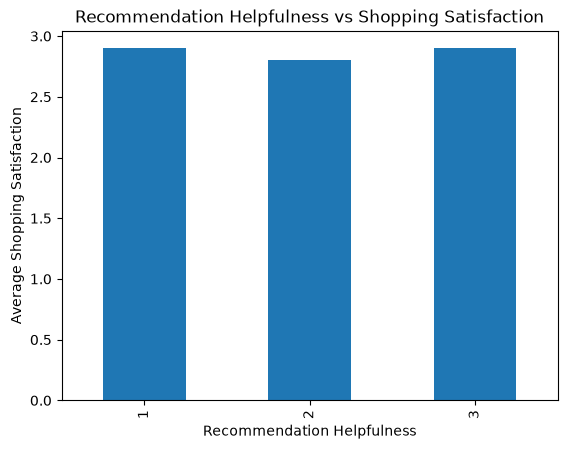

In [35]:
# Visualization

import matplotlib.pyplot as plt

df.groupby("Recommendation_Helpfulness")["Shopping_Satisfaction"].mean().plot(kind="bar")

plt.title("Recommendation Helpfulness vs Shopping Satisfaction")
plt.xlabel("Recommendation Helpfulness")
plt.ylabel("Average Shopping Satisfaction")
plt.show()

In [36]:
# Evaluate how review reliability and helpfulness impact overall ratings.
df.groupby("Review_Reliability")["Rating_Accuracy"].mean()


Review_Reliability
Heavily         3.193333
Moderately      3.031447
Never           2.762195
Occasionally    3.232394
Rarely          3.221622
Name: Rating_Accuracy, dtype: float64

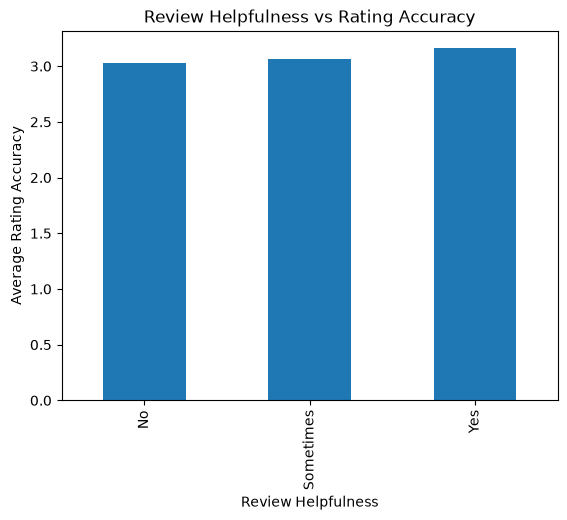

In [37]:
# Visualization
df.groupby("Review_Helpfulness")["Rating_Accuracy"].mean().plot(kind="bar")

plt.title("Review Helpfulness vs Rating Accuracy")
plt.xlabel("Review Helpfulness")
plt.ylabel("Average Rating Accuracy")
plt.show()

In [38]:
# Identify trends in how often customers engage with or trust personalized 
# recommendations.

df["Personalized_Recommendation_Frequency"].value_counts()  

Personalized_Recommendation_Frequency
No           279
Yes          261
Sometimes    260
Name: count, dtype: int64

In [39]:
df["Recommendation_Helpfulness"].value_counts()

Recommendation_Helpfulness
1    276
3    265
2    259
Name: count, dtype: int64

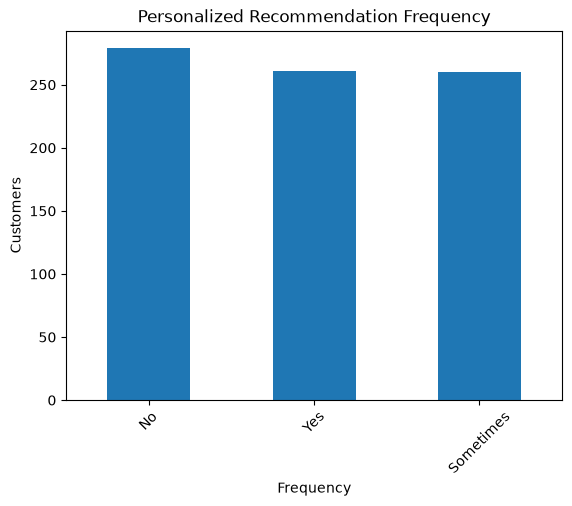

In [40]:
# Visualization

df["Personalized_Recommendation_Frequency"].value_counts().plot(kind="bar")

plt.title("Personalized Recommendation Frequency")
plt.xlabel("Frequency")
plt.ylabel("Customers")
plt.xticks(rotation=45)
plt.show()

In [41]:
# Suggest actionable insights for improving eBay’s recommendation system. 
# Improve personalized recommendations using customer purchase history.
# Recommend products based on browsing behavior and previous searches.
# Display highly rated and reliable products more frequently.
# Reduce irrelevant recommendations by improving recommendation algorithms.
# Encourage customers to leave verified reviews to improve recommendation quality.

In [42]:
# Task 5: Visualization and Reporting..........................
# Create attractive visualizations (bar charts, heatmaps, pie charts) for:
# Purchase categories:
# Split multiple categories into separate rows

purchase_category = (
    df["Purchase_Categories"]
    .str.split(";")
    .explode()
)

In [43]:
# Count each category

purchase_category.value_counts()

Purchase_Categories
Clothing and Fashion          450
Home and Kitchen              421
Beauty and Personal Care      418
others                        390
Groceries and Gourmet Food    366
Name: count, dtype: int64

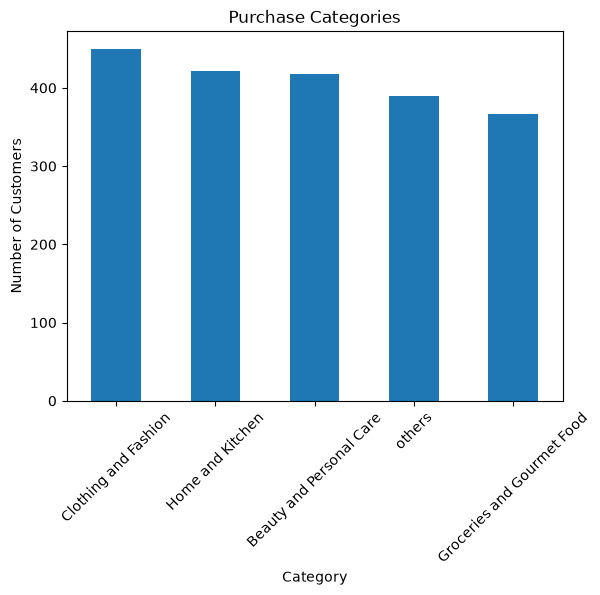

In [44]:
# Visualization
import matplotlib.pyplot as plt

purchase_category.value_counts().plot(kind="bar")

plt.title("Purchase Categories")
plt.xlabel("Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()

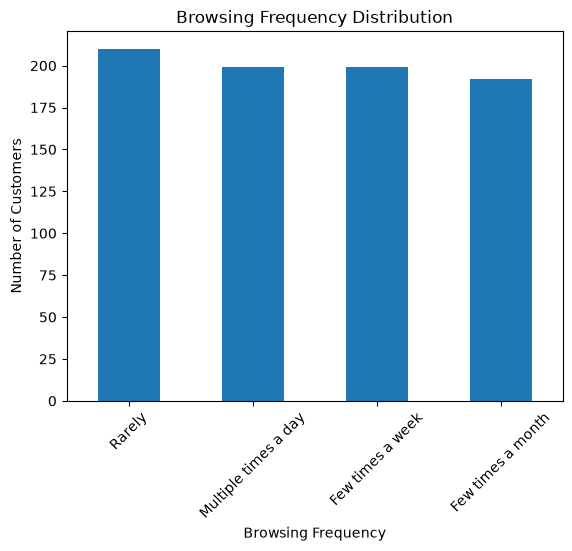

In [45]:
# Browsing frequency distribution:
df["Browsing_Frequency"].value_counts().plot(kind="bar")

plt.title("Browsing Frequency Distribution")
plt.xlabel("Browsing Frequency")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.show()

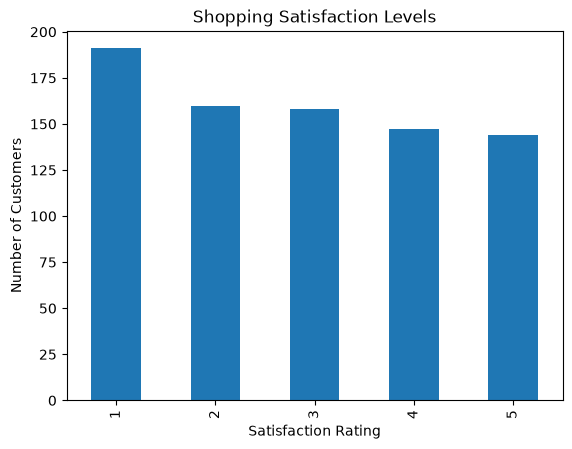

In [46]:
# Satisfaction Levels:
df["Shopping_Satisfaction"].value_counts().sort_index().plot(kind="bar")

plt.title("Shopping Satisfaction Levels")
plt.xlabel("Satisfaction Rating")
plt.ylabel("Number of Customers")
plt.show()

In [47]:
# Correlation between recommendation usefulness and satisfaction:
# Correlation Matrix:
correlation = df[["Recommendation_Helpfulness",
                  "Shopping_Satisfaction"]].corr()

print(correlation)

                            Recommendation_Helpfulness  Shopping_Satisfaction
Recommendation_Helpfulness                    1.000000              -0.000501
Shopping_Satisfaction                        -0.000501               1.000000


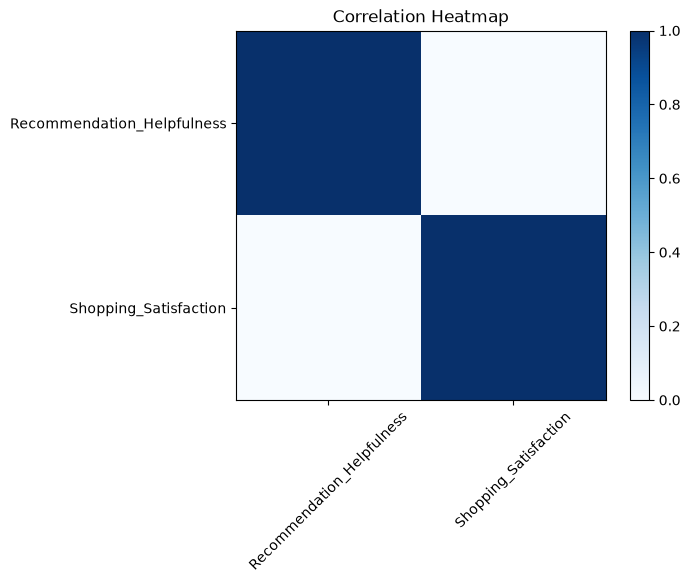

In [48]:
# Visualization:
import matplotlib.pyplot as plt

plt.imshow(correlation, cmap="Blues")

plt.colorbar()

plt.xticks([0,1],
           ["Recommendation_Helpfulness",
            "Shopping_Satisfaction"],
           rotation=45)

plt.yticks([0,1],
           ["Recommendation_Helpfulness",
            "Shopping_Satisfaction"])

plt.title("Correlation Heatmap")
plt.show()

In [49]:
# Summarize findings in a clear and visually appealing report format
# Findings
# Customer purchases are mainly concentrated in a few popular product categories.
# Most customers browse products a few times a month or once a week.
# Shopping satisfaction is generally moderate to high.
# Customers who find recommendations helpful tend to report higher shopping satisfaction.
# Personalized recommendations and customer reviews play an important role in improving the shopping experience.